# AR Bias in Panel Models

Julian Hsu

Created: 12-nov-2026

This notebook isolates one question: **how does the auto-regressive strength of the outcome affect the bias and the precision of a panel treatment-effect estimate, when the analysis stays at the daily level?**

We simulate panel data where the outcome follows an AR(1) process and estimate the effect of a treatment with a two-way fixed effects (TWFE) regression, at the daily level only â€” no aggregation. We compare three specifications at each AR level:
1. **TWFE**: the standard diff-in-diff regression with unit and time fixed effects, no lagged outcome.
2. **TWFE + lag**: the same regression controlling for the lagged outcome (a dynamic panel specification).
3. **lag, no unit FE**: the lagged-outcome model with time fixed effects only, omitting the unit fixed effects.

We compare the bias and precision of these two approaches, varying the strength of the AR process.

### Model Setup

We generate synthetic panel data of $N$ users observed daily:

$$y_{it} = \alpha y_{i,t-1} + \gamma W_{it} + \nu_i + \tau_{it} + \epsilon_{it}$$

where $\alpha$ is the AR coefficient we vary, $\gamma$ is the treatment effect of interest and $W_{it}$ equals one for treated users after treatment starts, $\nu_i$ is a unit-level fixed effect, $\tau_{it}$ is a day-specific shock, and $\epsilon_{it} \sim N(0,\sigma)$ is unexplainable noise.


In [2]:
import os
os.environ['NUMBA_DISABLE_JIT'] = '1'  # llvmlite JIT crashes on this machine; pyfixest falls back to pure python

import numpy as np
import pandas as pd

%matplotlib inline

import matplotlib.pyplot as plt
import seaborn as sns

from pyfixest import feols

import warnings
warnings.filterwarnings('ignore')

In [3]:
def dgp(N=None, preT=None, pstT=None, ar=0.50, atet=1,
        error_std=None, micro_periods=1, sel_sd=1):
    '''
    Generate a daily panel.

    sel_sd: treatment assignment rule. If None, treatment is assigned randomly
    to half the units (baseline). Otherwise, units are assigned based on the
    z-scored outcome in the last pre-treatment period:
        treated_unit = (z + N(0, sel_sd)) > 0
    so sel_sd = 0 is a hard median split on the lagged outcome (maximum
    selection); larger values approach random assignment.
    '''
    totalT = (preT+pstT)*micro_periods
    ## Unit fixed Effects
    unit_effect = np.random.uniform(-1,1,N)

    ## Time effects
    t_effect = np.random.uniform(-1,1,(totalT,N))

    ## Error Draws
    eps = np.random.normal(0,error_std,(totalT,N))

    ## Post Period Indicator
    post = (np.arange(totalT) >= preT*micro_periods).astype(float)

    ## Construct the panel and make it an AR process
    ## Phase 1: pre-treatment periods, no treatment
    y = np.zeros((totalT,N))
    prey = np.zeros(N)
    for t in range(preT*micro_periods):
        y[t] = ar*prey + t_effect[t] + unit_effect + eps[t]
        prey = y[t]

    ## Treatment assignment based on the last pre-period outcome
    y_pre = y[preT*micro_periods-1]
    z = (y_pre - y_pre.mean())/y_pre.std()
    treated_unit = ((z + np.random.normal(0,sel_sd,N)) > 0).astype(float)

    ## Interaction
    W = post[:,None]*treated_unit[None,:]

    ## Phase 2: post-treatment periods, treatment switched on
    for t in range(preT*micro_periods, totalT):
        y[t] = ar*prey + atet*W[t] + t_effect[t] + unit_effect + eps[t]
        prey = y[t]

    return pd.DataFrame({'unitid':np.tile(np.arange(N),totalT),
                         't':np.repeat(np.arange(totalT),N),
                         'W':W.ravel(),
                         'post':np.repeat(post,N),
                         'treatment_unit':np.tile(treated_unit,totalT),
                         'y':y.ravel()})

In [4]:
def did_twfe(data=None, use_lag=False):
    """TWFE DiD on the daily data (no aggregation) via PyFixest feols.
    use_lag=True adds the lagged outcome as a control."""
    dg = data.sort_values(['unitid','t']).copy()
    if use_lag:
        dg['y_lag'] = dg.groupby('unitid')['y'].shift()
        dg = dg.dropna(subset=['y_lag']).reset_index(drop=True)
        fit = feols("y ~ W + y_lag | unitid + t", data=dg, vcov="iid")
    else:
        fit = feols("y ~ W  | unitid + t", data=dg, vcov="iid")
    return pd.DataFrame(index=[0], data={'atet':fit.coef()['W'],
                                         'se':fit.se()['W']})

def did_timefe_lag(data=None):
    """Regression with the lagged outcome and time fixed effects only
    (no unit fixed effects), via PyFixest feols."""
    dg = data.sort_values(['unitid','t']).copy()
    dg['y_lag'] = dg.groupby('unitid')['y'].shift()
    dg = dg.dropna(subset=['y_lag']).reset_index(drop=True)
    fit = feols("y ~ W + y_lag | t", data=dg, vcov="iid")
    return pd.DataFrame(index=[0], data={'atet':fit.coef()['W'],
                                         'se':fit.se()['W']})

In [5]:
## Quick check on one simulated dataset: all three specifications
df = dgp(N=30,preT=5,pstT=3,ar=0.5,atet=2,error_std=1)
pd.concat([did_twfe(data=df, use_lag=False).assign(model='TWFE'),
           did_twfe(data=df, use_lag=True).assign(model='TWFE + lag'),
           did_timefe_lag(data=df).assign(model='lag, no unit FE')])

,atet,se,model
0,2.536275,0.325691,TWFE
0,1.769321,0.362837,TWFE + lag
0,1.552208,0.307935,"lag, no unit FE"


### Near Mandatory DiD Graph 


In [6]:
## Quick check on one simulated dataset: all three specifications
df = dgp(N=30,preT=10,pstT=3,ar=0.0,atet=2, error_std=0.05)
df_plot = df.groupby(['treatment_unit', 't'])['y'].mean().to_frame()
df_plot.reset_index(inplace=True)


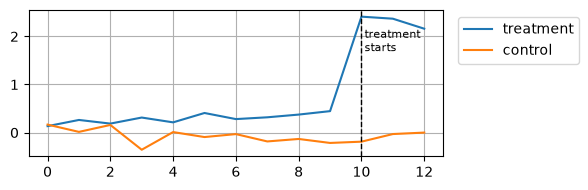

In [7]:
fig,ax = plt.subplots(ncols=1,nrows=1, figsize=(6,2))
ax.plot(df_plot.loc[df_plot.treatment_unit==1].t,         df_plot.loc[df_plot.treatment_unit==1].y,
        label='treatment')
ax.plot(df_plot.loc[df_plot.treatment_unit==0].t,         df_plot.loc[df_plot.treatment_unit==0].y,
        label='control')

## Vertical line at the first treated period
treat_t = df.loc[df.post==1, 't'].min()
ax.axvline(treat_t, color='k', ls='--', lw=1)
ax.text(treat_t+0.1, df_plot['y'].max()*0.90, 'treatment\nstarts',
        fontsize=8, va='top')

ax.grid()
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

### Explaining how AR processes impacts data
Plot the average of the control trends across different AR specifications

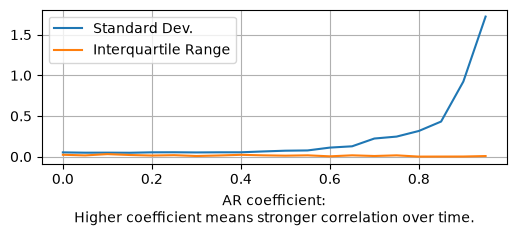

In [8]:
ar_list = np.arange(0,1, 0.05)

df_std = pd.DataFrame()
for ar_ in ar_list:
    df = dgp(N=500,preT=20,pstT=20,ar=ar_,atet=2,error_std=0)
    ## Just control units 
    df_plot = df.loc[df['treatment_unit']==0].groupby('t')['y'].mean()

    ## variance over time units 
    std_ = np.std(df_plot)
    p25 = np.percentile(df_plot, 0.25)
    p75 = np.percentile(df_plot,0.75)
    df_std = pd.concat([df_std, pd.DataFrame(index=[ar_], data={'std':std_, 'p25':p25, 'p75':p75}) ] )
    
fig,ax = plt.subplots(figsize=(6,2))
ax.plot(df_std.index, df_std['std'], label='Standard Dev.')
ax.plot(df_std.index, df_std['p75'] - df_std['p25'], label='Interquartile Range')

ax.grid()
ax.set_ylabel('')
ax.set_xlabel('AR coefficient:\nHigher coefficient means stronger correlation over time.')
ax.legend()



### Simulation Design

We simulate 100 datasets at each AR level. Within a simulation round, every AR setting uses the same random draws, so differences across AR settings are not due to different noise. For each dataset we estimate the treatment effect three times: TWFE without the lagged outcome, TWFE with it, and the lagged-outcome model with time fixed effects only (no unit fixed effects). The true treatment effect is 2.

Treatment assignment varies along a second axis, `sel_sd`. At `sel_sd = None` assignment is random (baseline). Otherwise, units are treated when `z + N(0, sel_sd) > 0`, where `z` is the z-scored outcome in the last pre-treatment period. `sel_sd = 0` is a hard median split on the lagged outcome (maximum selection on the lag); larger values approach random assignment. Because the lagged outcome contains the unit effect and past shocks, this makes W fail strict exogeneity, opening the channel for Nickell bias to contaminate the treatment coefficient.

In [9]:
atet_ = 2
sim_rounds = 200
ar_list = [0, 0.10, 0.35, 0.50, 0.60, 0.70, 0.80, 0.90]

In [10]:
model_list = ['TWFE', 'TWFE + lag', 'lag, no unit FE']

rows = []
for ar_ in ar_list:
    for s in range(sim_rounds):
        df = dgp(N=200, preT=10, pstT=3, ar=ar_, atet=atet_,
                    error_std=1, sel_sd=1)
        for m in model_list:
            if m == 'TWFE':
                twfe_result = did_twfe(data=df, use_lag=False)
            elif m == 'TWFE + lag':
                twfe_result = did_twfe(data=df, use_lag=True)
            else:
                twfe_result = did_timefe_lag(data=df)
            rows.append({'ar':ar_, 
                            'model':m, 'sim':s,
                            'atet':twfe_result['atet'].iloc[0],
                            'se':twfe_result['se'].iloc[0]})

df_r = pd.DataFrame(rows)
df_r['diff'] = df_r['atet'] - atet_

### Bias as a function of the AR coefficient and of selection strength

In [11]:
model_list_plot = ['TWFE','TWFE + lag']
model_color = {'TWFE':'coral'
               , 'TWFE + lag': 'seagreen'
               , 'lag, no unit FE':'magenta'}


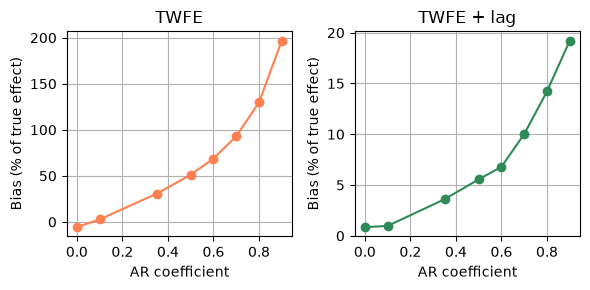

In [12]:
fig, ax = plt.subplots(ncols=len(model_list_plot), nrows=1, sharex=True, figsize=(3*len(model_list_plot), 3))
for i,m in enumerate(model_list_plot):
    sub = df_r[(df_r['model']==m)].groupby('ar')['diff'].mean()/atet_*100
    ax[i].plot(sub.index, sub.values, marker='o', color=model_color[m])
    ax[i].set_xlabel('AR coefficient')
    ax[i].set_ylabel('Bias (% of true effect)')
    ax[i].set_title(m)
    ax[i].legend(frameon=False)
    ax[i].grid()
plt.tight_layout()
plt.show()

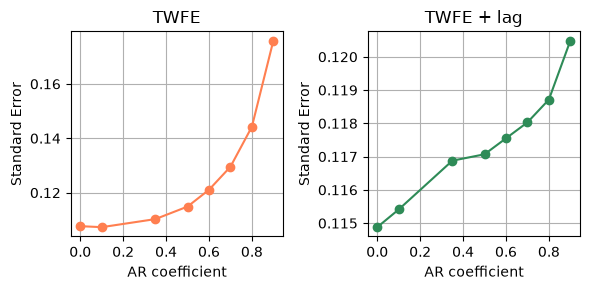

In [13]:
fig, ax = plt.subplots(ncols=len(model_list_plot), nrows=1, sharex=True, figsize=(3*len(model_list_plot), 3))
for i,m in enumerate(model_list_plot):
    sub = df_r[(df_r['model']==m) ].groupby('ar')['se'].mean()
    ax[i].plot(sub.index, sub.values, marker='o', color=model_color[m])
    ax[i].set_xlabel('AR coefficient')
    ax[i].set_ylabel('Standard Error')
    ax[i].set_title(m)
    ax[i].legend(frameon=False)
    ax[i].grid()
plt.tight_layout()
plt.show()

In [14]:
model_list_plot = ['TWFE','TWFE + lag', 'lag, no unit FE']


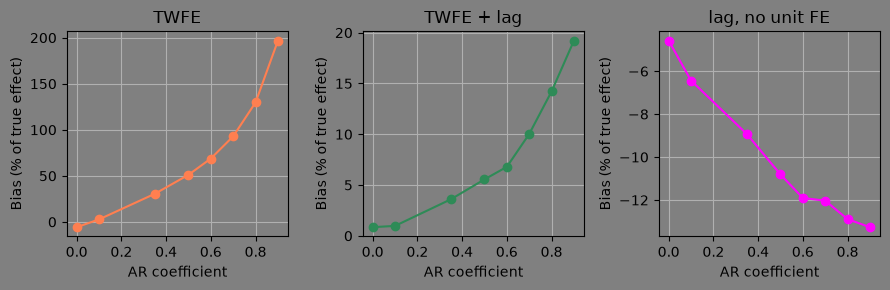

In [15]:
fig, ax = plt.subplots(ncols=len(model_list_plot), nrows=1, sharex=True, figsize=(3*len(model_list_plot), 3))
for i,m in enumerate(model_list_plot):
    sub = df_r[(df_r['model']==m)].groupby('ar')['diff'].mean()/atet_*100
    ax[i].plot(sub.index, sub.values, marker='o', color=model_color[m])
    ax[i].set_xlabel('AR coefficient')
    ax[i].set_ylabel('Bias (% of true effect)')
    ax[i].set_title(m)
    ax[i].legend(frameon=False)
    ax[i].grid()
    ax[i].set_facecolor("grey")  
fig.set_facecolor("grey") 
plt.tight_layout()
plt.show()

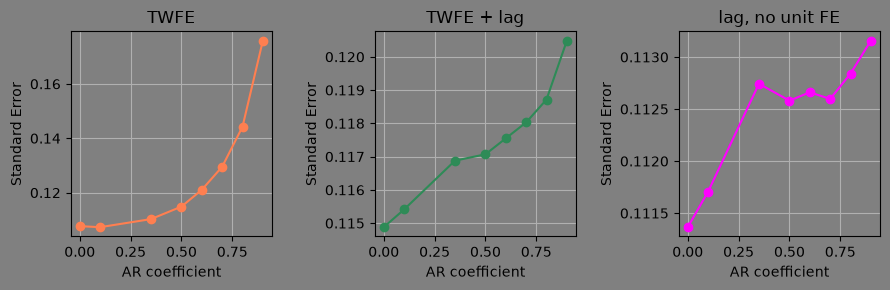

In [16]:
fig, ax = plt.subplots(ncols=len(model_list_plot), nrows=1, sharex=True, figsize=(3*len(model_list_plot), 3))
for i,m in enumerate(model_list_plot):
    sub = df_r[(df_r['model']==m) ].groupby('ar')['se'].mean()
    ax[i].plot(sub.index, sub.values, marker='o', color=model_color[m])
    ax[i].set_xlabel('AR coefficient')
    ax[i].set_ylabel('Standard Error')
    ax[i].set_title(m)
    ax[i].legend(frameon=False)
    ax[i].grid()
    ax[i].set_facecolor("grey")   
fig.set_facecolor("grey")  
plt.tight_layout()
plt.show()

### Bias as a function of the time span

Nickell bias is a small-sample (short-T) bias, so it should shrink as the panel gets longer. We freeze the AR coefficient at 0.5 and the selection rule at `sel_sd = 0` (hard median split on the lagged outcome, the case where the Nickell channel is fully open), and only stretch the calendar: `preT = 10*x` and `pstT = 3*x` for `x` in `[1, 1.5, 2, 2.5, 5]`, so the longest panel has 65 time periods per unit. We estimate only the TWFE + lag model and plot the bias against x.

In [17]:
## Bias of TWFE + lag as the panel gets longer, at AR = 0.5 and sel_sd = 0.
ar_ = 0.50
x_list = np.arange(1, 10)

rows = []
for x in x_list:
    preT_x, pstT_x = int(10*x), int(3*x)
    for s in range(sim_rounds*2):
        df = dgp(N=200, preT=preT_x, pstT=pstT_x, ar=ar_, atet=atet_,
                 error_std=1)
        twfe_result = did_twfe(data=df, use_lag=True)
        rows.append({'x':x, 'sim':s,
                     'atet':twfe_result['atet'].iloc[0],
                     'se':twfe_result['se'].iloc[0]})

df_x = pd.DataFrame(rows)


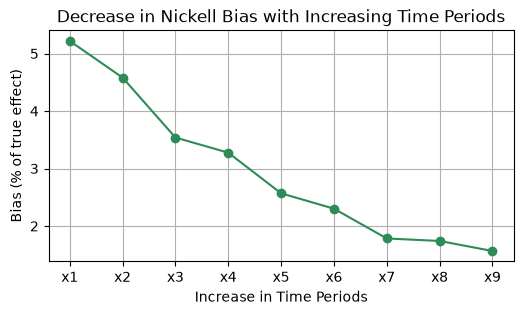

In [18]:

df_x['diff'] = df_x['atet'] - atet_

sub = df_x.groupby('x')['diff'].mean()/atet_*100


fig, ax = plt.subplots(figsize=(6,3))
ax.plot(sub.index, sub.values, marker='o', color = model_color['TWFE + lag'])
ax.set_xticks(x_list)
ax.set_xticklabels(['x'+str(e) for e in x_list])
ax.set_xlabel('Increase in Time Periods')
ax.set_ylabel('Bias (% of true effect)')
ax.set_title('Decrease in Nickell Bias with Increasing Time Periods')
ax.grid()
plt.show()